# CareerPrep AI — NLP-Based Job Description Matching

## Objective
To develop an NLP-based system that compares a student's skills with the skills and requirements mentioned in a job description.

## How It Works
1. Accept a job description as input.
2. Process the text using Natural Language Processing (NLP).
3. Identify important skills and keywords.
4. Compare the extracted skills with the student's existing skills.
5. Identify matching skills and skill gaps.
6. Generate a job-match score and improvement suggestions.

## Technologies
- Python
- Pandas
- Natural Language Processing (NLP)
- Scikit-learn

## Expected Outcome
The system will help students understand how well their current skill set matches a job opportunity and identify areas where they need improvement.

In [1]:
%pip install pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
job_description = """
We are looking for a Python Developer.

The candidate should have knowledge of Python programming,
SQL databases, Data Structures and Algorithms,
Git and GitHub, problem solving, and basic Machine Learning.

The candidate should also understand object-oriented programming
and be able to work with data using Pandas and NumPy.
"""

print("Job Description:")
print(job_description)

Job Description:

We are looking for a Python Developer.

The candidate should have knowledge of Python programming,
SQL databases, Data Structures and Algorithms,
Git and GitHub, problem solving, and basic Machine Learning.

The candidate should also understand object-oriented programming
and be able to work with data using Pandas and NumPy.



In [4]:
student_profile = {
    "name": "Shivangi",
    "skills": [
        "Python",
        "SQL",
        "Git and GitHub",
        "Problem Solving",
        "Pandas"
    ]
}

print("Student Name:", student_profile["name"])
print("Current Skills:", student_profile["skills"])

Student Name: Shivangi
Current Skills: ['Python', 'SQL', 'Git and GitHub', 'Problem Solving', 'Pandas']


In [5]:
skill_database = [
    "Python",
    "Java",
    "C++",
    "SQL",
    "Data Structures",
    "Algorithms",
    "Git and GitHub",
    "Problem Solving",
    "Machine Learning",
    "Object-Oriented Programming",
    "Pandas",
    "NumPy",
    "HTML",
    "CSS",
    "JavaScript"
]

print("Available Skills:")
for skill in skill_database:
    print("-", skill)

Available Skills:
- Python
- Java
- C++
- SQL
- Data Structures
- Algorithms
- Git and GitHub
- Problem Solving
- Machine Learning
- Object-Oriented Programming
- Pandas
- NumPy
- HTML
- CSS
- JavaScript


In [6]:
required_skills = []

job_text = job_description.lower()

for skill in skill_database:
    if skill.lower() in job_text:
        required_skills.append(skill)

print("Skills Required by the Job:")
for skill in required_skills:
    print("-", skill)

Skills Required by the Job:
- Python
- SQL
- Data Structures
- Algorithms
- Git and GitHub
- Problem Solving
- Machine Learning
- Object-Oriented Programming
- Pandas
- NumPy


In [7]:
student_skills = student_profile["skills"]

matched_skills = []
missing_skills = []

for skill in required_skills:
    if skill in student_skills:
        matched_skills.append(skill)
    else:
        missing_skills.append(skill)

print("MATCHED SKILLS:")
for skill in matched_skills:
    print("-", skill)

print("\nMISSING SKILLS:")
for skill in missing_skills:
    print("-", skill)

print("\nTotal Required Skills:", len(required_skills))
print("Matched Skills:", len(matched_skills))
print("Missing Skills:", len(missing_skills))

MATCHED SKILLS:
- Python
- SQL
- Git and GitHub
- Problem Solving
- Pandas

MISSING SKILLS:
- Data Structures
- Algorithms
- Machine Learning
- Object-Oriented Programming
- NumPy

Total Required Skills: 10
Matched Skills: 5
Missing Skills: 5


In [8]:
student_text = " ".join(student_profile["skills"])
required_text = " ".join(required_skills)

print("Student Skills Text:")
print(student_text)

print("\nJob Required Skills Text:")
print(required_text)

Student Skills Text:
Python SQL Git and GitHub Problem Solving Pandas

Job Required Skills Text:
Python SQL Data Structures Algorithms Git and GitHub Problem Solving Machine Learning Object-Oriented Programming Pandas NumPy


In [9]:
documents = [student_text, required_text]

vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(documents)

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

print("\nVocabulary:")
print(vectorizer.get_feature_names_out())

TF-IDF Matrix Shape: (2, 17)

Vocabulary:
['algorithms' 'and' 'data' 'git' 'github' 'learning' 'machine' 'numpy'
 'object' 'oriented' 'pandas' 'problem' 'programming' 'python' 'solving'
 'sql' 'structures']


In [10]:
similarity_score = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)

print("Cosine Similarity Score:", round(similarity_score[0][0] * 100, 2), "%")

Cosine Similarity Score: 55.71 %


In [11]:
total_required = len(required_skills)
total_matched = len(matched_skills)

if total_required > 0:
    job_match_percentage = (total_matched / total_required) * 100
else:
    job_match_percentage = 0

print("JOB MATCH REPORT")
print("-------------------------")
print("Student:", student_profile["name"])
print("Target Job: Python Developer")
print("Required Skills:", total_required)
print("Matched Skills:", total_matched)
print("Missing Skills:", len(missing_skills))
print("Job Match Percentage:", round(job_match_percentage, 2), "%")

JOB MATCH REPORT
-------------------------
Student: Shivangi
Target Job: Python Developer
Required Skills: 10
Matched Skills: 5
Missing Skills: 5
Job Match Percentage: 50.0 %


In [12]:
print("PERSONALISED SKILL IMPROVEMENT PLAN")
print("-----------------------------------")

if missing_skills:
    print("You should focus on learning these skills:\n")

    for index, skill in enumerate(missing_skills, start=1):
        print(f"{index}. {skill}")

else:
    print("Congratulations! You have all the required skills.")

PERSONALISED SKILL IMPROVEMENT PLAN
-----------------------------------
You should focus on learning these skills:

1. Data Structures
2. Algorithms
3. Machine Learning
4. Object-Oriented Programming
5. NumPy


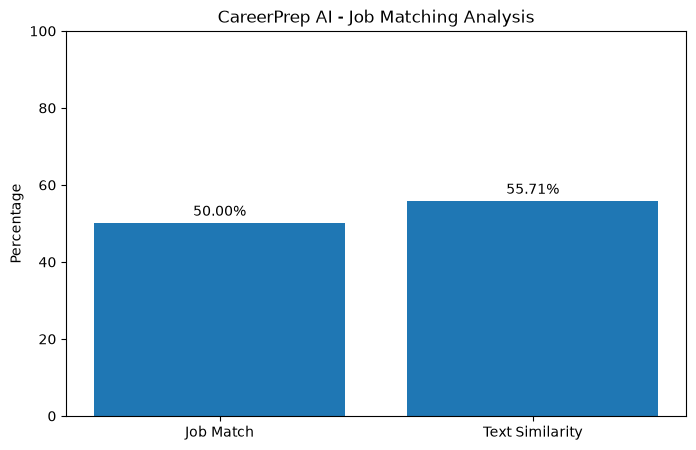

In [13]:
import matplotlib.pyplot as plt

scores = [
    job_match_percentage,
    similarity_score[0][0] * 100
]

labels = [
    "Job Match",
    "Text Similarity"
]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, scores)

plt.ylim(0, 100)
plt.ylabel("Percentage")
plt.title("CareerPrep AI - Job Matching Analysis")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"{height:.2f}%",
        ha="center"
    )

plt.show()

In [14]:
plt.savefig("job_matching_chart.png", dpi=300, bbox_inches="tight")

print("Job matching chart saved successfully!")

Job matching chart saved successfully!


<Figure size 640x480 with 0 Axes>

## Conclusion

The NLP-Based Job Description Matching System successfully compares a student's existing skills with the requirements of a job description.

The system uses keyword-based skill extraction, TF-IDF vectorisation and cosine similarity to analyse the text. It calculates job skill coverage, identifies missing skills and generates personalised improvement recommendations.

This module demonstrates how Natural Language Processing can support students in understanding job requirements and improving their career readiness.

**Future Enhancements:**
- Support multiple job descriptions.
- Improve skill extraction using NLP techniques.
- Integrate course recommendations with the identified skill gaps.
- Develop a user-friendly student interface.